# Phase 2: Exploratory Data Analysis (EDA)

**Project:** Health Insurance Cross-Sell Prediction Using Machine Learning  
**Objective:** Explore customer patterns, relationships with `Response`, and distributions using Matplotlib and Seaborn.

All 13 graphs generated in this notebook are saved to `Outputs/graphs/` so they can be used directly in your college project report and presentation.

## Step 1: Import Libraries & Load Dataset

We import `pandas`, `numpy`, `matplotlib.pyplot`, and `seaborn`, configure consistent figure styling, and load `Dataset/train.csv`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean visual theme for all plots
sns.set_theme(style='whitegrid', context='notebook', palette='Set2')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 150

DATA_PATH = os.path.join('..', 'Dataset', 'train.csv')
GRAPHS_DIR = os.path.join('..', 'Outputs', 'graphs')
os.makedirs(GRAPHS_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df['Response_Label'] = df['Response'].map({0: 'Not Interested (0)', 1: 'Interested (1)'})
print(f'Loaded dataset: {df.shape[0]:,} rows x {df.shape[1]-1} original columns')

Loaded dataset: 381,109 rows x 12 original columns


## Graph 1: Target Variable Distribution (`Response = 0` vs `Response = 1`)

This bar chart shows how many customers responded `0` (Not Interested) versus `1` (Interested in vehicle insurance).

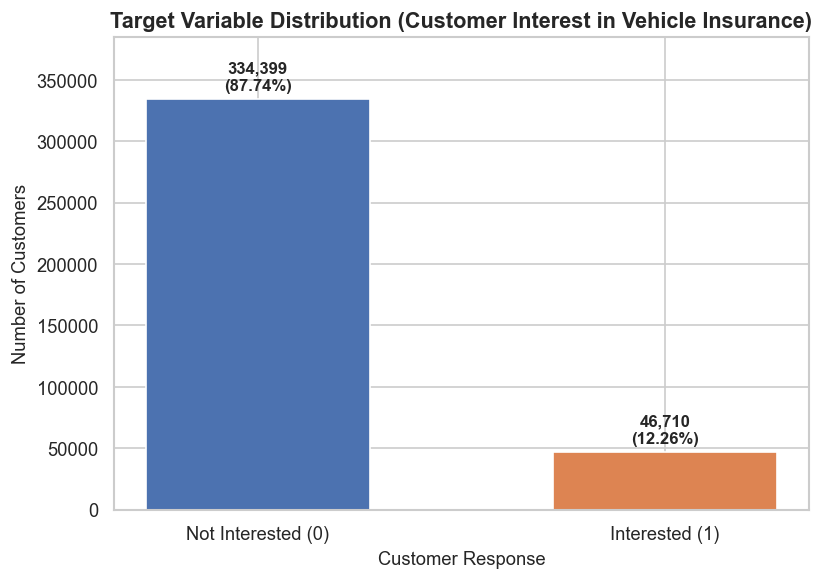

Response=0: 334,399 (87.74%), Response=1: 46,710 (12.26%)


In [2]:
counts = df['Response'].value_counts().sort_index()
pcts = df['Response'].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(['Not Interested (0)', 'Interested (1)'], counts.values, color=['#4C72B0', '#DD8452'], width=0.55)
ax.set_title('Target Variable Distribution (Customer Interest in Vehicle Insurance)', fontsize=13, fontweight='bold')
ax.set_xlabel('Customer Response', fontsize=11)
ax.set_ylabel('Number of Customers', fontsize=11)
ax.set_ylim(0, counts.max() * 1.15)

for bar, count, pct in zip(bars, counts.values, pcts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5000,
            f'{count:,}\n({pct:.2f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '01_target_distribution.png'))
plt.show()
print(f'Response=0: {counts[0]:,} ({pcts[0]:.2f}%), Response=1: {counts[1]:,} ({pcts[1]:.2f}%)')

## Graph 2: Gender Distribution (Overall & by Response)

This two-panel figure shows (left) the overall count of Male vs. Female customers and (right) the interest rate (`Response = 1` %) within each gender.

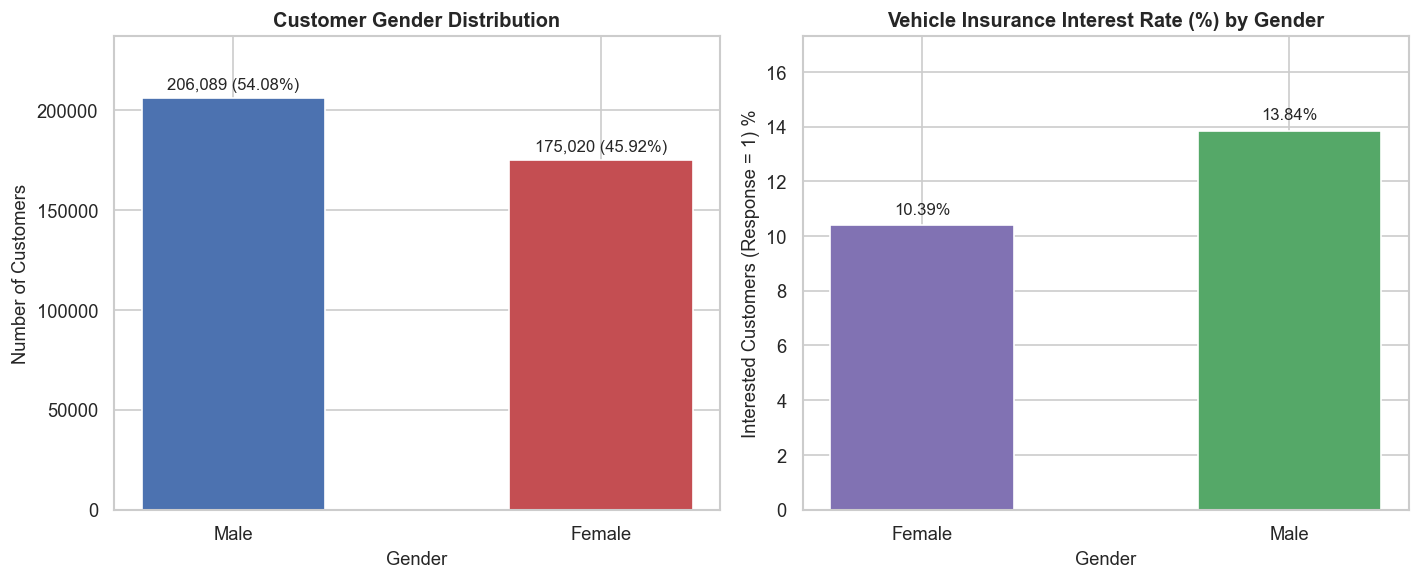

Response       0      1     All
Gender                         
Female    156835  18185  175020
Male      177564  28525  206089
All       334399  46710  381109

Response=1 % by Gender:
 Gender
Female    10.39
Male      13.84
Name: 1, dtype: float64


In [3]:
gender_ct = pd.crosstab(df['Gender'], df['Response'], normalize='index') * 100
gender_counts = df['Gender'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: overall gender count
bars0 = axes[0].bar(gender_counts.index, gender_counts.values, color=['#4C72B0', '#C44E52'], width=0.5)
axes[0].set_title('Customer Gender Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Gender', fontsize=11)
axes[0].set_ylabel('Number of Customers', fontsize=11)
axes[0].set_ylim(0, gender_counts.max() * 1.15)
for bar, val in zip(bars0, gender_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 3000,
                 f'{val:,} ({val/len(df)*100:.2f}%)', ha='center', va='bottom', fontsize=10)

# Right: interest rate by gender
bars1 = axes[1].bar(gender_ct.index, gender_ct[1].values, color=['#8172B3', '#55A868'], width=0.5)
axes[1].set_title('Vehicle Insurance Interest Rate (%) by Gender', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Gender', fontsize=11)
axes[1].set_ylabel('Interested Customers (Response = 1) %', fontsize=11)
axes[1].set_ylim(0, gender_ct[1].max() * 1.25)
for bar, val in zip(bars1, gender_ct[1].values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.3, f'{val:.2f}%', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '02_gender_distribution.png'))
plt.show()
print(pd.crosstab(df['Gender'], df['Response'], margins=True))
print('\nResponse=1 % by Gender:\n', gender_ct[1].round(2))

## Graph 3: Age Distribution

This histogram with a Kernel Density Estimate (KDE) curve shows how customer ages are distributed across the dataset.

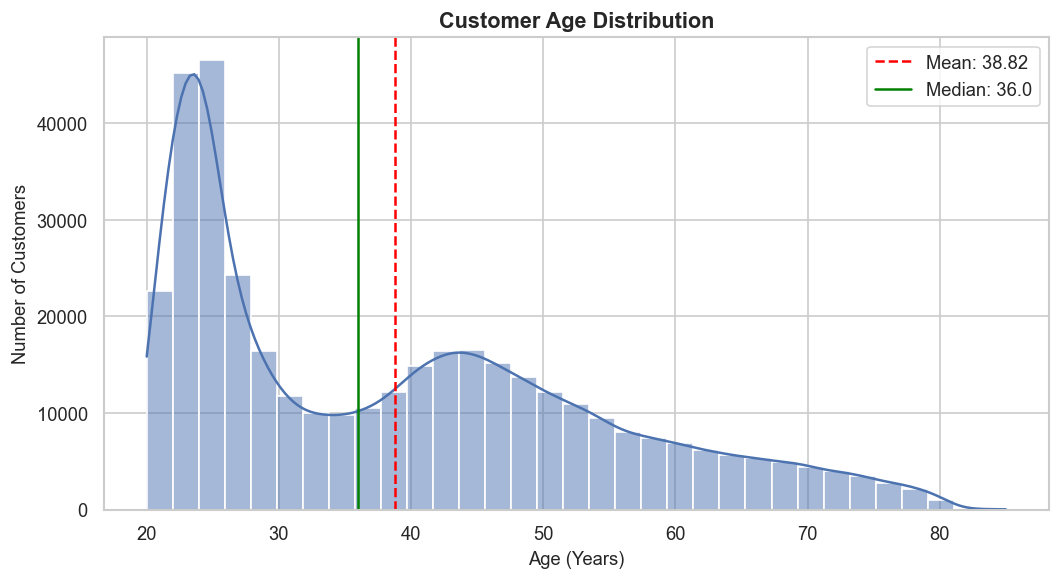

count    381109.00
mean         38.82
std          15.51
min          20.00
25%          25.00
50%          36.00
75%          49.00
max          85.00
Name: Age, dtype: float64


In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df['Age'], bins=33, kde=True, color='#4C72B0', ax=ax)
ax.axvline(df['Age'].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean: {df['Age'].mean():.2f}")
ax.axvline(df['Age'].median(), color='green', linestyle='-', linewidth=1.5, label=f"Median: {df['Age'].median():.1f}")
ax.set_title('Customer Age Distribution', fontsize=13, fontweight='bold')
ax.set_xlabel('Age (Years)', fontsize=11)
ax.set_ylabel('Number of Customers', fontsize=11)
ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '03_age_distribution.png'))
plt.show()
print(df['Age'].describe().round(2))

## Graph 4: Age versus Customer Response

We compare `Age` across `Response = 0` and `Response = 1` using an overlapping density/histogram plot and a boxplot, plus interest rates grouped by age brackets.

C:\Users\ABHAY\AppData\Local\Temp\ipykernel_1852\2910723764.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Response_Label', y='Age', palette=['#4C72B0', '#DD8452'], ax=axes[1])


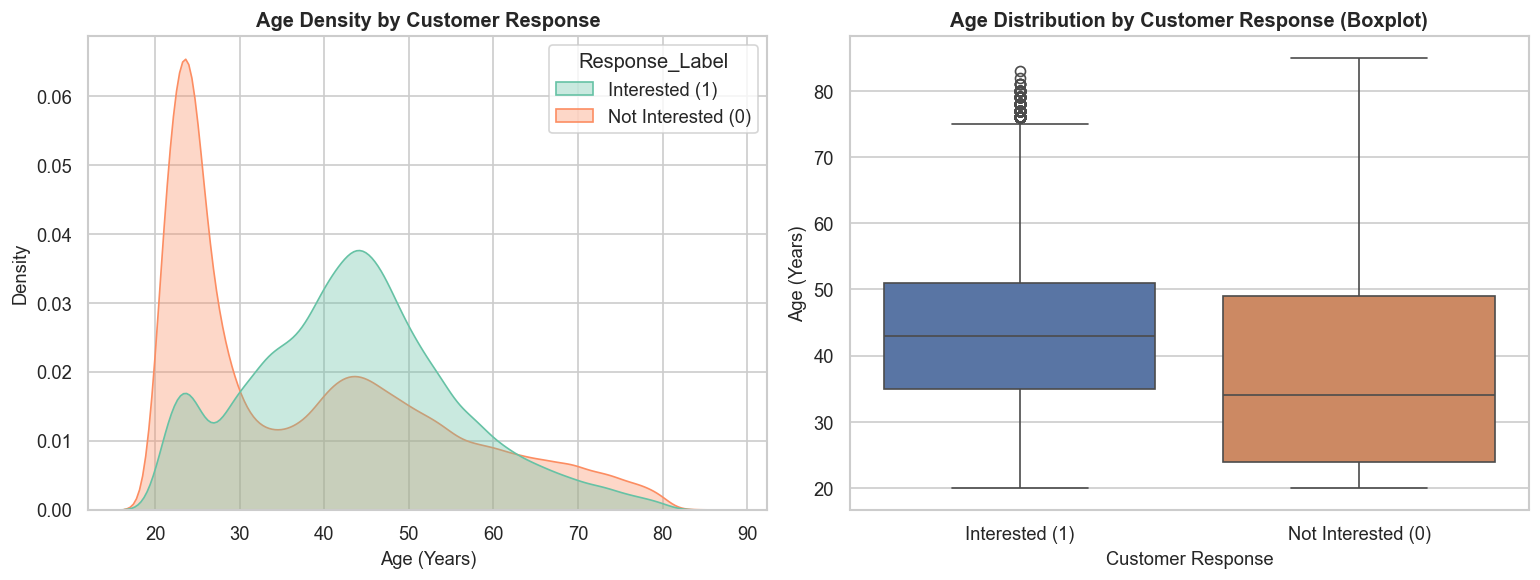

Age statistics by Response:
             count   mean    std   min   25%   50%   75%   max
Response                                                      
0         334399.0  38.18  15.82  20.0  24.0  34.0  49.0  85.0
1          46710.0  43.44  12.17  20.0  35.0  43.0  51.0  83.0

Interest Rate (%) by Age Group:
        count   mean
Age                 
20-30  161461   4.45
31-40   55163  21.02
41-50   75941  21.10
51-60   45305  17.03
61-85   43239   9.69


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.kdeplot(data=df, x='Age', hue='Response_Label', common_norm=False, fill=True, alpha=0.35, ax=axes[0])
axes[0].set_title('Age Density by Customer Response', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Age (Years)', fontsize=11)
axes[0].set_ylabel('Density', fontsize=11)

sns.boxplot(data=df, x='Response_Label', y='Age', palette=['#4C72B0', '#DD8452'], ax=axes[1])
axes[1].set_title('Age Distribution by Customer Response (Boxplot)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Customer Response', fontsize=11)
axes[1].set_ylabel('Age (Years)', fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '04_age_vs_response.png'))
plt.show()

print('Age statistics by Response:')
print(df.groupby('Response')['Age'].describe().round(2))
age_bins = pd.cut(df['Age'], bins=[19, 30, 40, 50, 60, 85], labels=['20-30', '31-40', '41-50', '51-60', '61-85'])
print('\nInterest Rate (%) by Age Group:')
print((df.groupby(age_bins, observed=False)['Response'].agg(['count', 'mean']) * [1, 100]).round(2))

## Graph 5: Vehicle Age Distribution (Overall & by Response)

This two-panel chart displays how many customers own `< 1 Year`, `1-2 Year`, and `> 2 Years` old vehicles, and the interest rate (`Response = 1` %) for each category.

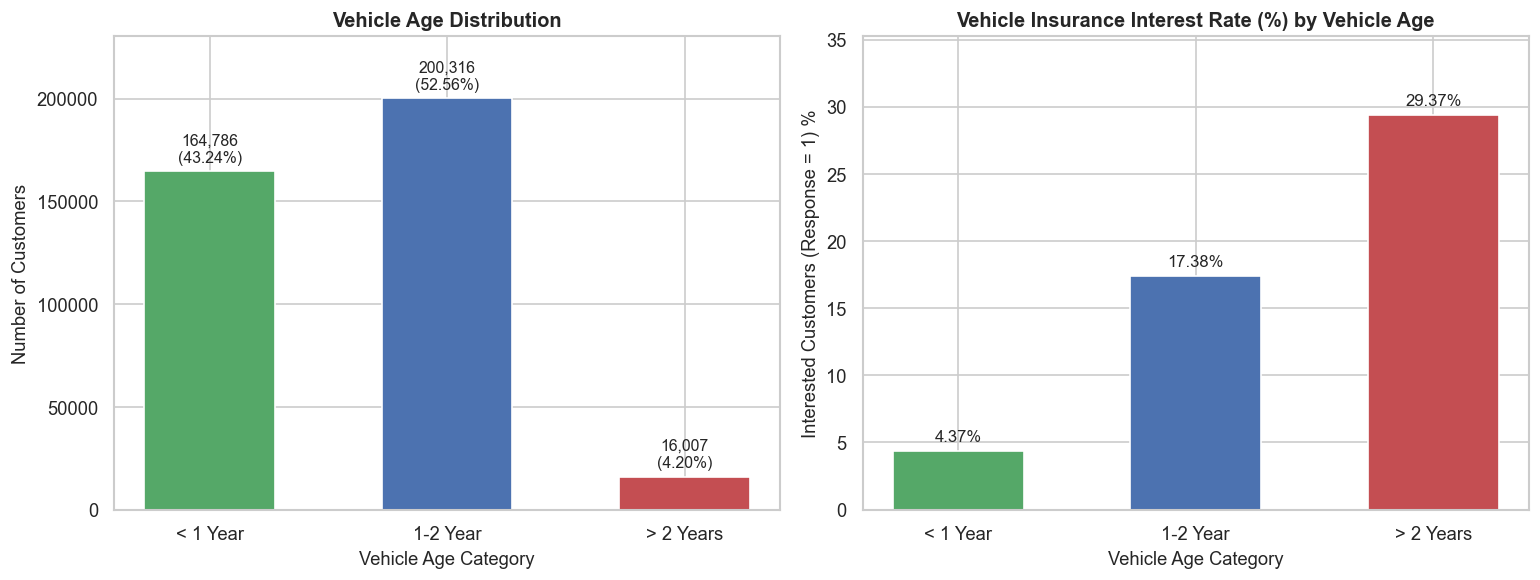

Response          0      1     All
Vehicle_Age                       
1-2 Year     165510  34806  200316
< 1 Year     157584   7202  164786
> 2 Years     11305   4702   16007
All          334399  46710  381109

Interest Rate (%) by Vehicle_Age:
 Vehicle_Age
< 1 Year      4.37
1-2 Year     17.38
> 2 Years    29.37
Name: Response, dtype: float64


In [6]:
order_va = ['< 1 Year', '1-2 Year', '> 2 Years']
va_counts = df['Vehicle_Age'].value_counts().reindex(order_va)
va_rate = df.groupby('Vehicle_Age')['Response'].mean().reindex(order_va) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bars0 = axes[0].bar(va_counts.index, va_counts.values, color=['#55A868', '#4C72B0', '#C44E52'], width=0.55)
axes[0].set_title('Vehicle Age Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Vehicle Age Category', fontsize=11)
axes[0].set_ylabel('Number of Customers', fontsize=11)
axes[0].set_ylim(0, va_counts.max() * 1.15)
for bar, val in zip(bars0, va_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 3000,
                 f'{val:,}\n({val/len(df)*100:.2f}%)', ha='center', va='bottom', fontsize=9.5)

bars1 = axes[1].bar(va_rate.index, va_rate.values, color=['#55A868', '#4C72B0', '#C44E52'], width=0.55)
axes[1].set_title('Vehicle Insurance Interest Rate (%) by Vehicle Age', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Vehicle Age Category', fontsize=11)
axes[1].set_ylabel('Interested Customers (Response = 1) %', fontsize=11)
axes[1].set_ylim(0, va_rate.max() * 1.2)
for bar, val in zip(bars1, va_rate.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.5, f'{val:.2f}%', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '05_vehicle_age_distribution.png'))
plt.show()
print(pd.crosstab(df['Vehicle_Age'], df['Response'], margins=True))
print('\nInterest Rate (%) by Vehicle_Age:\n', va_rate.round(2))

## Graph 6: Vehicle Damage versus Customer Response

This chart compares vehicle insurance interest between customers whose vehicle previously had damage (`Yes`) versus no damage (`No`).

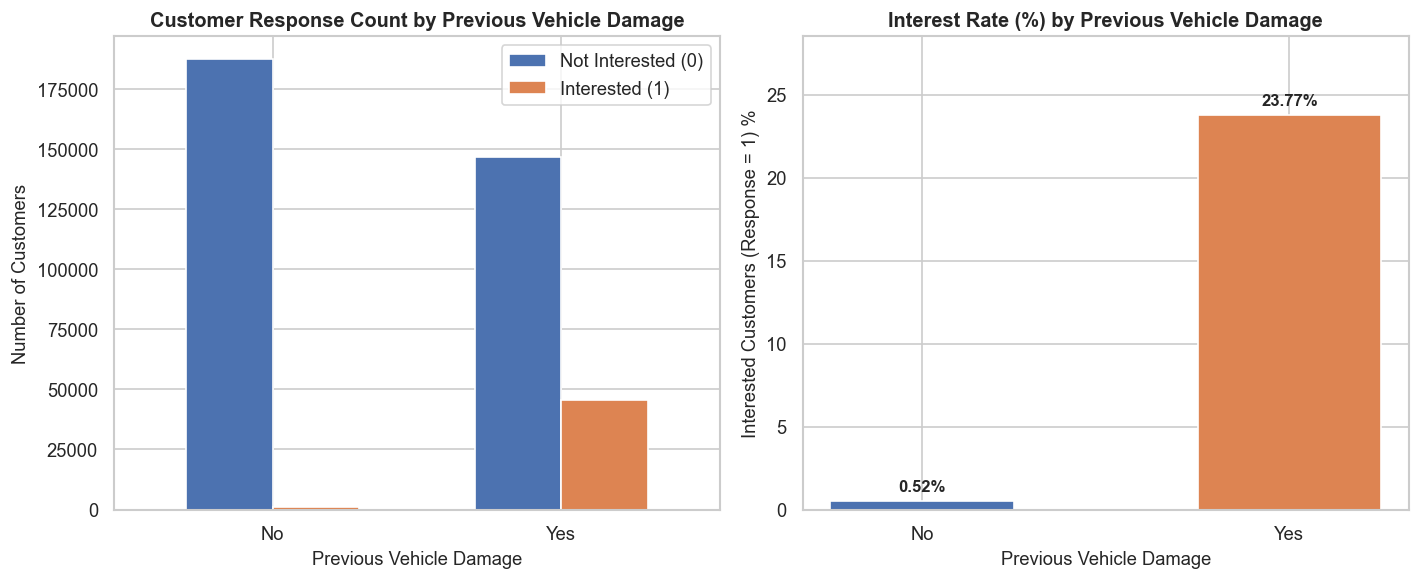

Response             0      1
Vehicle_Damage               
No              187714    982
Yes             146685  45728

Interest Rate (%) by Vehicle_Damage:
 Vehicle_Damage
No      0.52
Yes    23.77
Name: Response, dtype: float64


In [7]:
vd_ct = pd.crosstab(df['Vehicle_Damage'], df['Response'])
vd_rate = df.groupby('Vehicle_Damage')['Response'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

vd_ct.plot(kind='bar', ax=axes[0], color=['#4C72B0', '#DD8452'], width=0.6)
axes[0].set_title('Customer Response Count by Previous Vehicle Damage', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Previous Vehicle Damage', fontsize=11)
axes[0].set_ylabel('Number of Customers', fontsize=11)
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(['Not Interested (0)', 'Interested (1)'])

bars1 = axes[1].bar(vd_rate.index, vd_rate.values, color=['#4C72B0', '#DD8452'], width=0.5)
axes[1].set_title('Interest Rate (%) by Previous Vehicle Damage', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Previous Vehicle Damage', fontsize=11)
axes[1].set_ylabel('Interested Customers (Response = 1) %', fontsize=11)
axes[1].set_ylim(0, vd_rate.max() * 1.2)
for bar, val in zip(bars1, vd_rate.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.4, f'{val:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '06_vehicle_damage_vs_response.png'))
plt.show()
print(vd_ct)
print('\nInterest Rate (%) by Vehicle_Damage:\n', vd_rate.round(2))

## Graph 7: Previously Insured versus Customer Response

This chart compares customers who already have vehicle insurance (`Previously_Insured = 1`) against those who do not (`Previously_Insured = 0`).

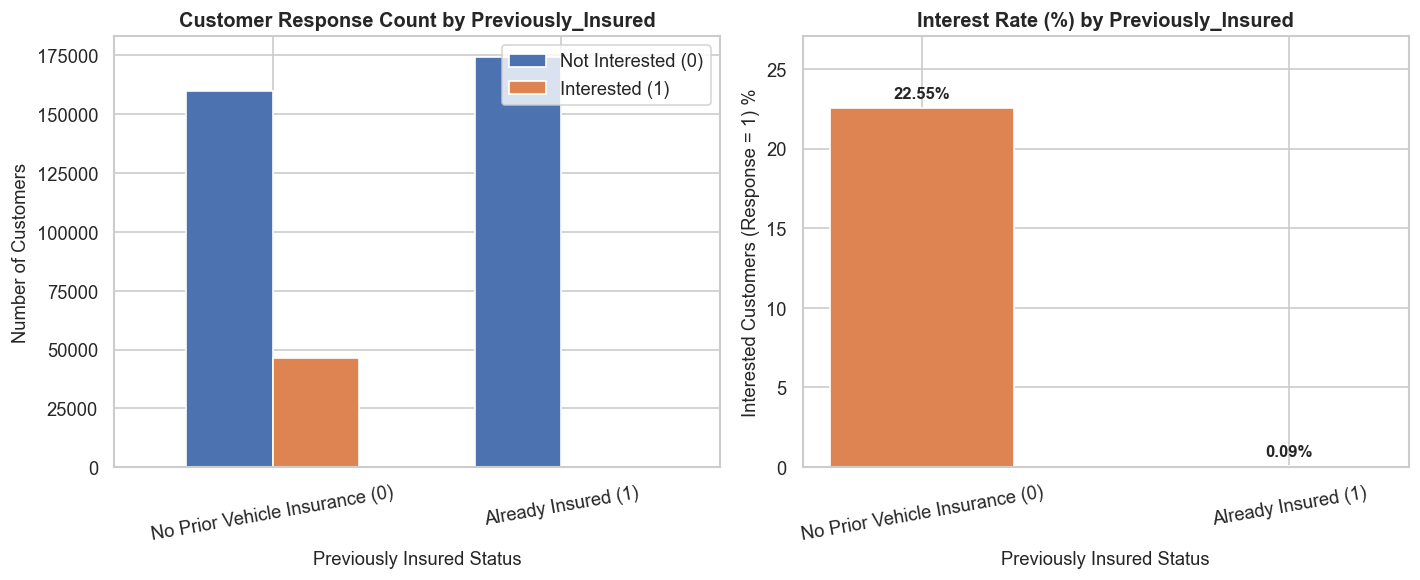

Response                 0      1
Previously_Insured               
0                   159929  46552
1                   174470    158

Interest Rate (%) by Previously_Insured:
 Previously_Insured
0    22.55
1     0.09
Name: Response, dtype: float64


In [8]:
pi_ct = pd.crosstab(df['Previously_Insured'], df['Response'])
pi_rate = df.groupby('Previously_Insured')['Response'].mean() * 100
labels_pi = ['No Prior Vehicle Insurance (0)', 'Already Insured (1)']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

pi_ct_named = pi_ct.copy()
pi_ct_named.index = labels_pi
pi_ct_named.plot(kind='bar', ax=axes[0], color=['#4C72B0', '#DD8452'], width=0.6)
axes[0].set_title('Customer Response Count by Previously_Insured', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Previously Insured Status', fontsize=11)
axes[0].set_ylabel('Number of Customers', fontsize=11)
axes[0].tick_params(axis='x', rotation=10)
axes[0].legend(['Not Interested (0)', 'Interested (1)'])

bars1 = axes[1].bar(labels_pi, pi_rate.values, color=['#DD8452', '#4C72B0'], width=0.5)
axes[1].set_title('Interest Rate (%) by Previously_Insured', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Previously Insured Status', fontsize=11)
axes[1].set_ylabel('Interested Customers (Response = 1) %', fontsize=11)
axes[1].set_ylim(0, pi_rate.max() * 1.2)
axes[1].tick_params(axis='x', rotation=10)
for bar, val in zip(bars1, pi_rate.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.4, f'{val:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '07_previously_insured_vs_response.png'))
plt.show()
print(pi_ct)
print('\nInterest Rate (%) by Previously_Insured:\n', pi_rate.round(2))

## Graph 8: Annual Premium Distribution

Because `Annual_Premium` has extreme high values up to `540,165`, we display both the full range (left) and a zoomed view up to the 99th percentile (right) so the bulk of customer premiums is clearly readable.

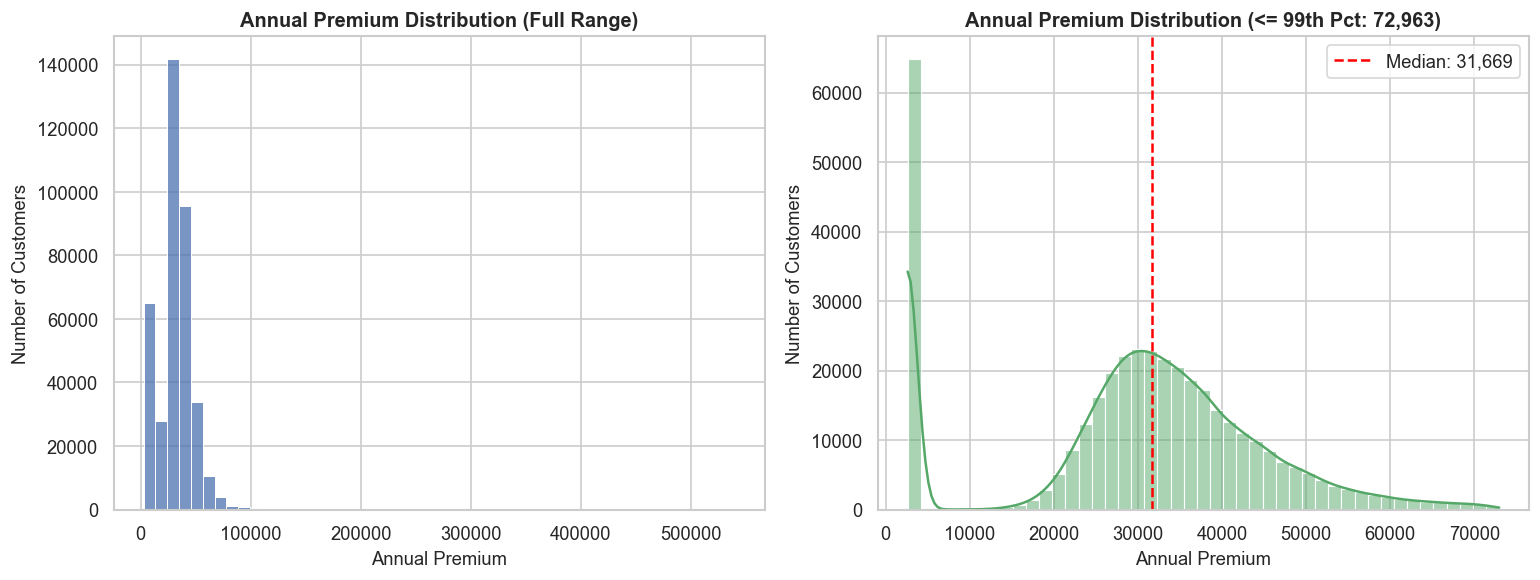

count    381109.00
mean      30564.39
std       17213.16
min        2630.00
25%       24405.00
50%       31669.00
75%       39400.00
max      540165.00
Name: Annual_Premium, dtype: float64
99th percentile: 72,963.00
Customers at minimum premium (2,630.0): 64,877 (17.02%)


In [9]:
p99 = df['Annual_Premium'].quantile(0.99)
min_prem_count = (df['Annual_Premium'] == 2630.0).sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df['Annual_Premium'], bins=50, color='#4C72B0', ax=axes[0])
axes[0].set_title('Annual Premium Distribution (Full Range)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Annual Premium', fontsize=11)
axes[0].set_ylabel('Number of Customers', fontsize=11)

sns.histplot(df[df['Annual_Premium'] <= p99]['Annual_Premium'], bins=45, kde=True, color='#55A868', ax=axes[1])
axes[1].axvline(df['Annual_Premium'].median(), color='red', linestyle='--', label=f"Median: {df['Annual_Premium'].median():,.0f}")
axes[1].set_title(f'Annual Premium Distribution (<= 99th Pct: {p99:,.0f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Annual Premium', fontsize=11)
axes[1].set_ylabel('Number of Customers', fontsize=11)
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '08_annual_premium_distribution.png'))
plt.show()
print(df['Annual_Premium'].describe().round(2))
print(f'99th percentile: {p99:,.2f}')
print(f'Customers at minimum premium (2,630.0): {min_prem_count:,} ({min_prem_count/len(df)*100:.2f}%)')

## Graph 9: Region Code Distribution (Top 15 Regions)

There are 53 unique `Region_Code` values. To keep the plot readable, we show the Top 15 regions by customer count along with their corresponding vehicle insurance interest rate (`Response = 1` %).

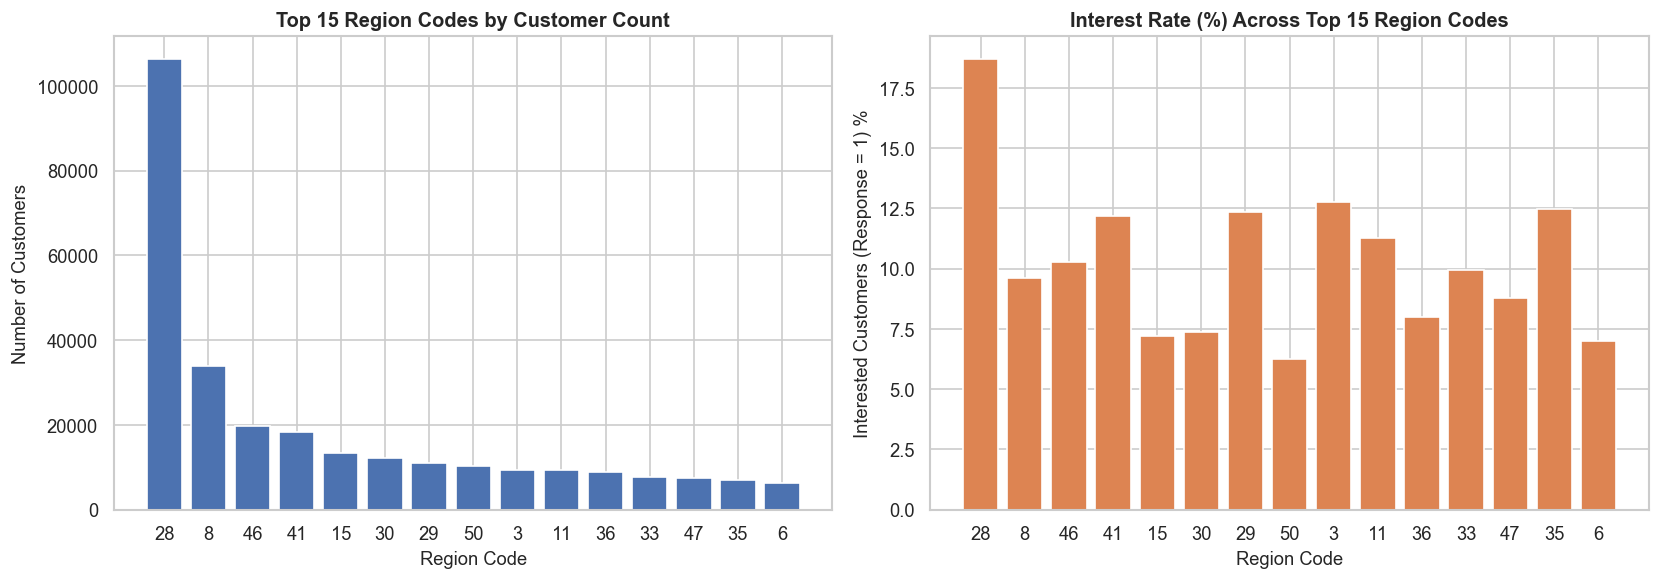

              Count  Share (%)  Interest_Rate (%)
Region_Code                                      
28.0         106415      27.92              18.72
8.0           33877       8.89               9.61
46.0          19749       5.18              10.29
41.0          18263       4.79              12.18
15.0          13308       3.49               7.20


In [10]:
top_regions = df['Region_Code'].value_counts().head(15)
region_rate = df.groupby('Region_Code')['Response'].mean().loc[top_regions.index] * 100
region_labels = [str(int(r)) for r in top_regions.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(region_labels, top_regions.values, color='#4C72B0')
axes[0].set_title('Top 15 Region Codes by Customer Count', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Region Code', fontsize=11)
axes[0].set_ylabel('Number of Customers', fontsize=11)

axes[1].bar(region_labels, region_rate.values, color='#DD8452')
axes[1].set_title('Interest Rate (%) Across Top 15 Region Codes', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Region Code', fontsize=11)
axes[1].set_ylabel('Interested Customers (Response = 1) %', fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '09_region_code_distribution.png'))
plt.show()

top5_reg_df = pd.DataFrame({'Count': top_regions.head(5), 'Share (%)': (top_regions.head(5)/len(df)*100).round(2), 'Interest_Rate (%)': region_rate.head(5).round(2)})
print(top5_reg_df)

## Graph 10: Policy Sales Channel Distribution (Top 15 Channels)

There are 155 unique `Policy_Sales_Channel` codes. We plot the Top 15 channels by customer volume alongside their interest rates (`Response = 1` %).

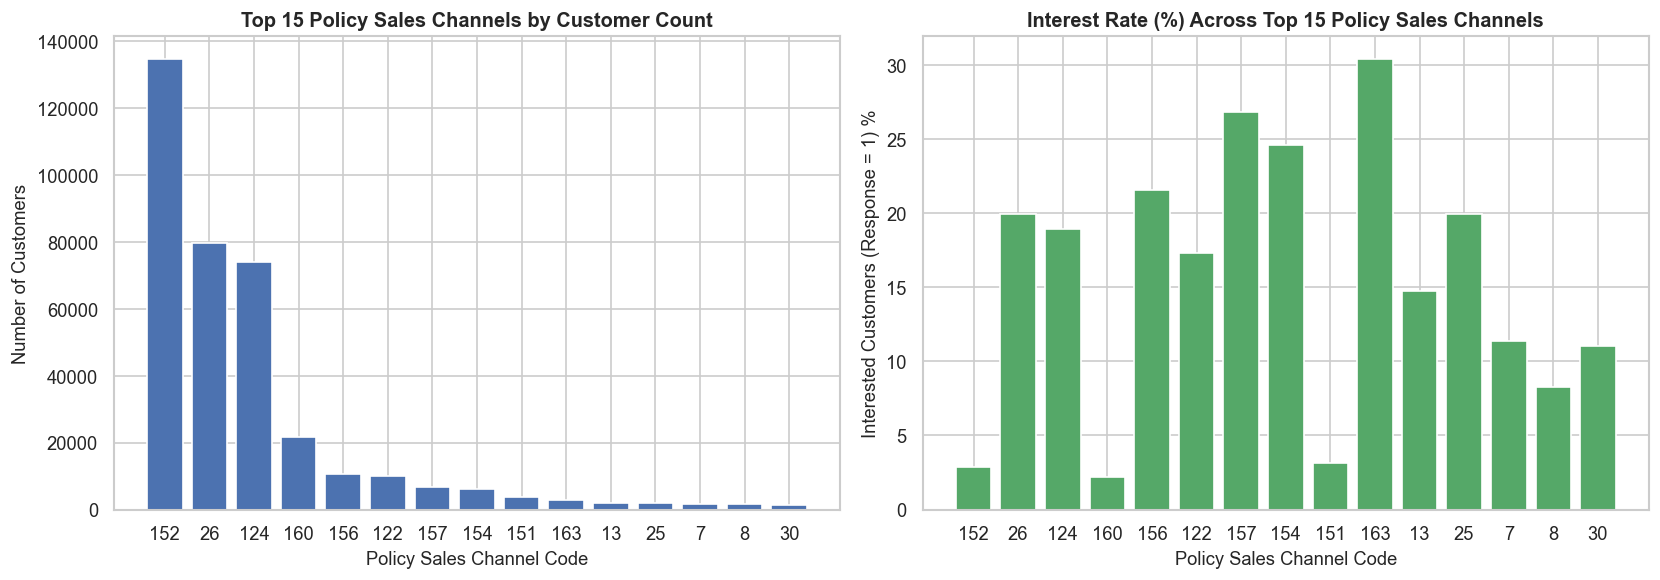

                       Count  Share (%)  Interest_Rate (%)
Policy_Sales_Channel                                      
152.0                 134784      35.37               2.86
26.0                   79700      20.91              19.94
124.0                  73995      19.42              18.91
160.0                  21779       5.71               2.18
156.0                  10661       2.80              21.55
122.0                   9930       2.61              17.32
157.0                   6684       1.75              26.84
154.0                   5993       1.57              24.60
151.0                   3885       1.02               3.14
163.0                   2893       0.76              30.42


In [11]:
top_channels = df['Policy_Sales_Channel'].value_counts().head(15)
channel_rate = df.groupby('Policy_Sales_Channel')['Response'].mean().loc[top_channels.index] * 100
channel_labels = [str(int(c)) for c in top_channels.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(channel_labels, top_channels.values, color='#4C72B0')
axes[0].set_title('Top 15 Policy Sales Channels by Customer Count', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Policy Sales Channel Code', fontsize=11)
axes[0].set_ylabel('Number of Customers', fontsize=11)

axes[1].bar(channel_labels, channel_rate.values, color='#55A868')
axes[1].set_title('Interest Rate (%) Across Top 15 Policy Sales Channels', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Policy Sales Channel Code', fontsize=11)
axes[1].set_ylabel('Interested Customers (Response = 1) %', fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '10_policy_sales_channel_distribution.png'))
plt.show()

top10_ch_df = pd.DataFrame({'Count': top_channels.head(10), 'Share (%)': (top_channels.head(10)/len(df)*100).round(2), 'Interest_Rate (%)': channel_rate.head(10).round(2)})
print(top10_ch_df)

## Graph 11: Vintage Distribution

`Vintage` measures how many days the customer has been associated with the company. We plot both the overall histogram and compare `Vintage` by `Response`.

C:\Users\ABHAY\AppData\Local\Temp\ipykernel_1852\1752819002.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Response_Label', y='Vintage', palette=['#4C72B0', '#DD8452'], ax=axes[1])


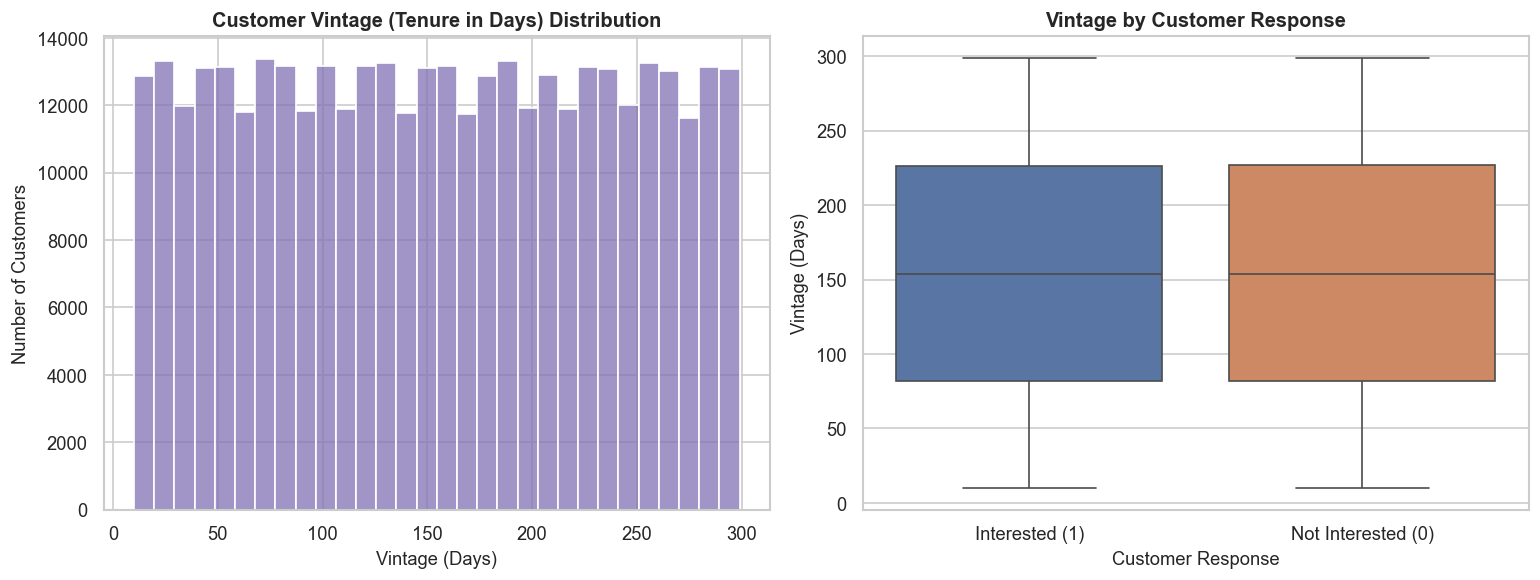

             count    mean    std   min   25%    50%    75%    max
Response                                                          
0         334399.0  154.38  83.66  10.0  82.0  154.0  227.0  299.0
1          46710.0  154.11  83.74  10.0  82.0  154.0  226.0  299.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df['Vintage'], bins=30, color='#8172B3', ax=axes[0])
axes[0].set_title('Customer Vintage (Tenure in Days) Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Vintage (Days)', fontsize=11)
axes[0].set_ylabel('Number of Customers', fontsize=11)

sns.boxplot(data=df, x='Response_Label', y='Vintage', palette=['#4C72B0', '#DD8452'], ax=axes[1])
axes[1].set_title('Vintage by Customer Response', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Customer Response', fontsize=11)
axes[1].set_ylabel('Vintage (Days)', fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '11_vintage_distribution.png'))
plt.show()
print(df.groupby('Response')['Vintage'].describe().round(2))

## Graph 12: Correlation Heatmap for Suitable Numerical Features

We compute Pearson correlations only on genuinely numerical/binary features (`Age`, `Driving_License`, `Previously_Insured`, `Annual_Premium`, `Vintage`, and `Response`). We intentionally exclude `id` (identifier) as well as `Region_Code` and `Policy_Sales_Channel` (nominal category codes whose numeric order has no mathematical meaning).

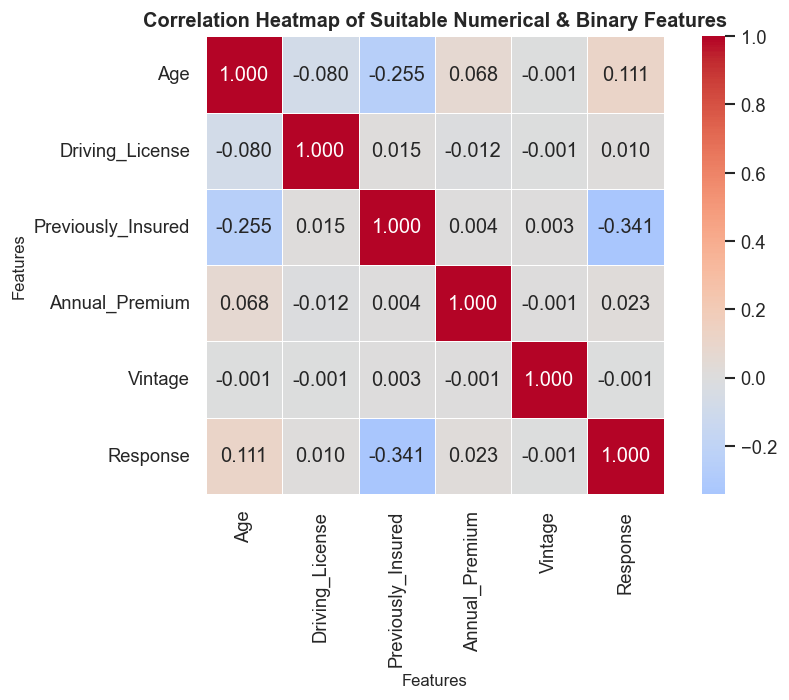

                       Age  Driving_License  Previously_Insured  \
Age                 1.0000          -0.0798             -0.2547   
Driving_License    -0.0798           1.0000              0.0150   
Previously_Insured -0.2547           0.0150              1.0000   
Annual_Premium      0.0675          -0.0119              0.0043   
Vintage            -0.0013          -0.0008              0.0025   
Response            0.1111           0.0102             -0.3412   

                    Annual_Premium  Vintage  Response  
Age                         0.0675  -0.0013    0.1111  
Driving_License            -0.0119  -0.0008    0.0102  
Previously_Insured          0.0043   0.0025   -0.3412  
Annual_Premium              1.0000  -0.0006    0.0226  
Vintage                    -0.0006   1.0000   -0.0011  
Response                    0.0226  -0.0011    1.0000  


In [13]:
corr_cols = ['Age', 'Driving_License', 'Previously_Insured', 'Annual_Premium', 'Vintage', 'Response']
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0, linewidths=0.5, square=True, ax=ax)
ax.set_title('Correlation Heatmap of Suitable Numerical & Binary Features', fontsize=12, fontweight='bold')
ax.set_xlabel('Features', fontsize=10)
ax.set_ylabel('Features', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '12_correlation_heatmap.png'))
plt.show()
print(corr_matrix.round(4))

## Graph 13: Comparing Interested vs. Non-Interested Customers

We summarize key differences between `Response = 1` (Interested) and `Response = 0` (Not Interested) across numerical averages and high-signal categorical drivers (`Previously_Insured` and `Vehicle_Damage` combined).

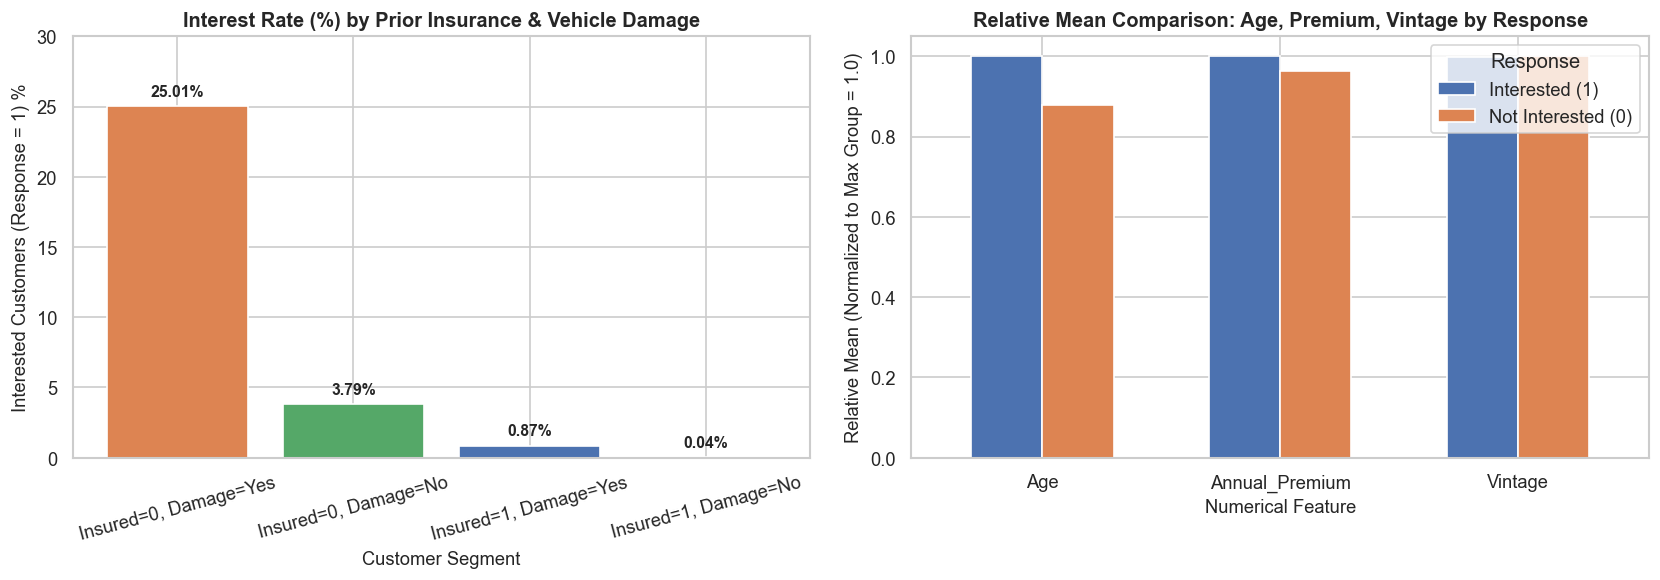

--- Segment Summary (Previously_Insured x Vehicle_Damage) ---
                        count  Interest_Rate (%)
Segment                                         
Insured=0, Damage=Yes  182491              25.01
Insured=0, Damage=No    23990               3.79
Insured=1, Damage=Yes    9922               0.87
Insured=1, Damage=No   164706               0.04

--- Mean & Median Comparison by Response ---
            Age        Annual_Premium          Vintage       
           mean median           mean   median    mean median
Response                                                     
0         38.18   34.0       30419.16  31504.0  154.38  154.0
1         43.44   43.0       31604.09  33002.0  154.11  154.0


In [14]:
# Combined segment: Previously_Insured x Vehicle_Damage
df['Segment'] = (
    'Insured=' + df['Previously_Insured'].astype(str) + ', Damage=' + df['Vehicle_Damage']
)
seg_summary = df.groupby('Segment')['Response'].agg(['count', 'mean']).sort_values('mean', ascending=False)
seg_summary['Interest_Rate (%)'] = seg_summary['mean'] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Interest rate across key segments
bars = axes[0].bar(seg_summary.index, seg_summary['Interest_Rate (%)'], color=['#DD8452', '#55A868', '#4C72B0', '#8172B3'])
axes[0].set_title('Interest Rate (%) by Prior Insurance & Vehicle Damage', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Customer Segment', fontsize=11)
axes[0].set_ylabel('Interested Customers (Response = 1) %', fontsize=11)
axes[0].tick_params(axis='x', rotation=15)
axes[0].set_ylim(0, seg_summary['Interest_Rate (%)'].max() * 1.2)
for bar, val in zip(bars, seg_summary['Interest_Rate (%)']):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.5, f'{val:.2f}%', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# Right: Mean Age & Mean Annual Premium normalized comparison
num_comp = df.groupby('Response_Label')[['Age', 'Annual_Premium', 'Vintage']].mean()
num_comp_norm = num_comp / num_comp.max()
num_comp_norm.T.plot(kind='bar', ax=axes[1], color=['#4C72B0', '#DD8452'], width=0.6)
axes[1].set_title('Relative Mean Comparison: Age, Premium, Vintage by Response', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Numerical Feature', fontsize=11)
axes[1].set_ylabel('Relative Mean (Normalized to Max Group = 1.0)', fontsize=11)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Response')

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '13_interested_vs_not_interested_comparison.png'))
plt.show()

print('--- Segment Summary (Previously_Insured x Vehicle_Damage) ---')
print(seg_summary[['count', 'Interest_Rate (%)']].round(2))
print('\n--- Mean & Median Comparison by Response ---')
print(df.groupby('Response')[['Age', 'Annual_Premium', 'Vintage']].agg(['mean', 'median']).round(2))

## Phase 2 Summary of Key EDA Findings

After executing this notebook, review the printed statistics and saved PNG charts in `Outputs/graphs/`:
- **`Previously_Insured` and `Vehicle_Damage` show the strongest association with `Response`:** Customers who do not already have vehicle insurance (`Previously_Insured = 0`) and who experienced past vehicle damage (`Vehicle_Damage = Yes`) have a dramatically higher interest rate.
- **`Age` and `Vehicle_Age` matter:** Middle-aged customers and owners of older vehicles (`1-2 Year` and `> 2 Years`) show noticeably higher interest rates than younger customers with `< 1 Year` vehicles.
- **`Policy_Sales_Channel` and `Region_Code` vary sharply:** Certain channels (such as channels `26`, `124`, `156`, etc.) and regions have substantially different interest rates than others (like channel `152`), making them valuable categorical predictors.
- **`Vintage` and `Annual_Premium` show minimal standalone difference:** Average `Vintage` is nearly identical between interested and non-interested customers (~154 days), and `Annual_Premium` is heavily right-skewed with a large cluster at `2,630.0`.